In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
y = df["G3"]

X_all = df.drop(columns=["G3"])
X_no_grades = df.drop(columns=["G1", "G2", "G3"])

def make_preprocessor(X):
    cat_cols = X.select_dtypes(include="object").columns.tolist()
    num_cols = X.select_dtypes(exclude="object").columns.tolist()
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

models = {
    "Dummy (predict mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "SVR": SVR(),
    "k-NN": KNeighborsRegressor(n_neighbors=7),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                              random_state=42, verbose=-1),
}

scoring = {"mae": "neg_mean_absolute_error",
           "rmse": "neg_root_mean_squared_error",
           "r2": "r2"}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

In [2]:
def run_all(X, label):
    rows = []
    for name, reg in models.items():
        pipe = Pipeline([("prep", make_preprocessor(X)), ("reg", reg)])
        res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({
            "Features": label,
            "Model": name,
            "MAE": -res["test_mae"].mean(),
            "RMSE": -res["test_rmse"].mean(),
            "R2": res["test_r2"].mean(),
            "R2 std": res["test_r2"].std(),
        })
    return pd.DataFrame(rows)

reg_results = pd.concat([
    run_all(X_all, "A: with G1, G2"),
    run_all(X_no_grades, "B: without G1, G2"),
], ignore_index=True).round(3)

reg_results.to_csv("../reports/regression_comparison.csv", index=False)

for label in reg_results["Features"].unique():
    print(f"\n=== {label} ===")
    print(reg_results[reg_results["Features"] == label]
          .drop(columns="Features")
          .sort_values("MAE")
          .to_string(index=False))


=== A: with G1, G2 ===
               Model   MAE  RMSE     R2  R2 std
       Random Forest 1.012 1.594  0.873   0.046
             XGBoost 1.057 1.667  0.861   0.046
       Decision Tree 1.059 1.935  0.809   0.075
            LightGBM 1.088 1.654  0.863   0.045
    Ridge Regression 1.360 2.030  0.798   0.042
                 SVR 1.598 2.604  0.668   0.067
                k-NN 2.015 2.819  0.613   0.060
Dummy (predict mean) 3.436 4.581 -0.015   0.014

=== B: without G1, G2 ===
               Model   MAE  RMSE     R2  R2 std
       Random Forest 2.938 3.900  0.257   0.133
             XGBoost 3.112 4.001  0.219   0.119
            LightGBM 3.120 4.017  0.212   0.123
                 SVR 3.164 4.280  0.112   0.082
                k-NN 3.292 4.397  0.059   0.129
    Ridge Regression 3.433 4.447  0.035   0.124
Dummy (predict mean) 3.436 4.581 -0.015   0.014
       Decision Tree 3.461 4.720 -0.093   0.213


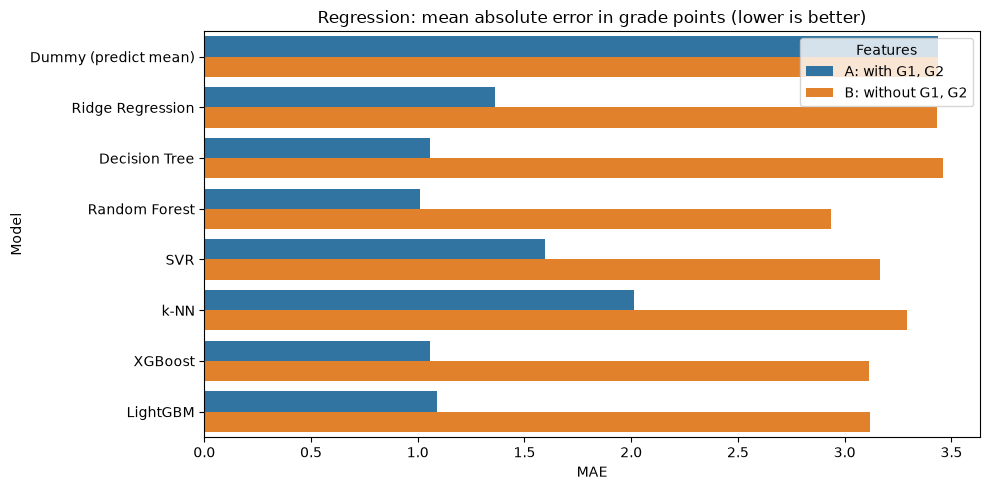

In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(data=reg_results, x="MAE", y="Model", hue="Features")
plt.title("Regression: mean absolute error in grade points (lower is better)")
plt.tight_layout()
plt.savefig("../reports/regression_comparison.png", dpi=200)
plt.show()